# `Library`

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

# `Data Loading & Understanding`

### Data Load

In [3]:
current_dir = os.getcwd()
parent_dir = os.path.dirname(current_dir)
file_path = os.path.join(parent_dir, "data", "mnist.npz")
df = np.load(file_path)
print(df.files)
x_train = df['x_train']
y_train = df['y_train']
x_test = df['x_test']
y_test = df['y_test']

['x_test', 'x_train', 'y_train', 'y_test']


### Data info

In [4]:
print('x_train shape(Images):', x_train.shape)
print('y_train shape(labels):', y_train.shape)
print('x_test shape(Images):', x_test.shape)
print('y_test shape(labels):', y_test.shape)
print('Image data type:', x_train.dtype)
print('Pixel min:', x_train.min(), '| Pixel max:', x_train.max())
print('Pixel min:', x_test.min(), '| Pixel max:', x_test.max())
print('Unique labels:', np.unique(y_train))

x_train shape(Images): (60000, 28, 28)
y_train shape(labels): (60000,)
x_test shape(Images): (10000, 28, 28)
y_test shape(labels): (10000,)
Image data type: uint8
Pixel min: 0 | Pixel max: 255
Pixel min: 0 | Pixel max: 255
Unique labels: [0 1 2 3 4 5 6 7 8 9]


### NULL Checking

In [5]:
print("x_train (null):", np.isnan(x_train).sum())
print("y_train (null):", np.isnan(y_train).sum())

x_train (null): 0
y_train (null): 0


### Duplicate Checking

In [6]:
flat = x_train.reshape(len(x_train), -1)
dup_count = len(flat) - len(np.unique(flat, axis=0))
print('Duplicate images in train:', dup_count)

Duplicate images in train: 0


### Leakage Checking (Between Train and Test)

In [7]:
train_flat = x_train.reshape(len(x_train), -1)
train_flat.shape

(60000, 784)

In [8]:
test_flat = x_test.reshape(len(x_test), -1)
test_flat.shape

(10000, 784)

In [9]:
train_set = set(map(tuple, train_flat))
leak = 0
for img in test_flat:
    if tuple(img) in train_set:
        leak += 1
print("Data Leakage(Between Train and Test):", leak)

Data Leakage(Between Train and Test): 0


# `Exploratory Data Analysis (EDA)`

### Sample Images

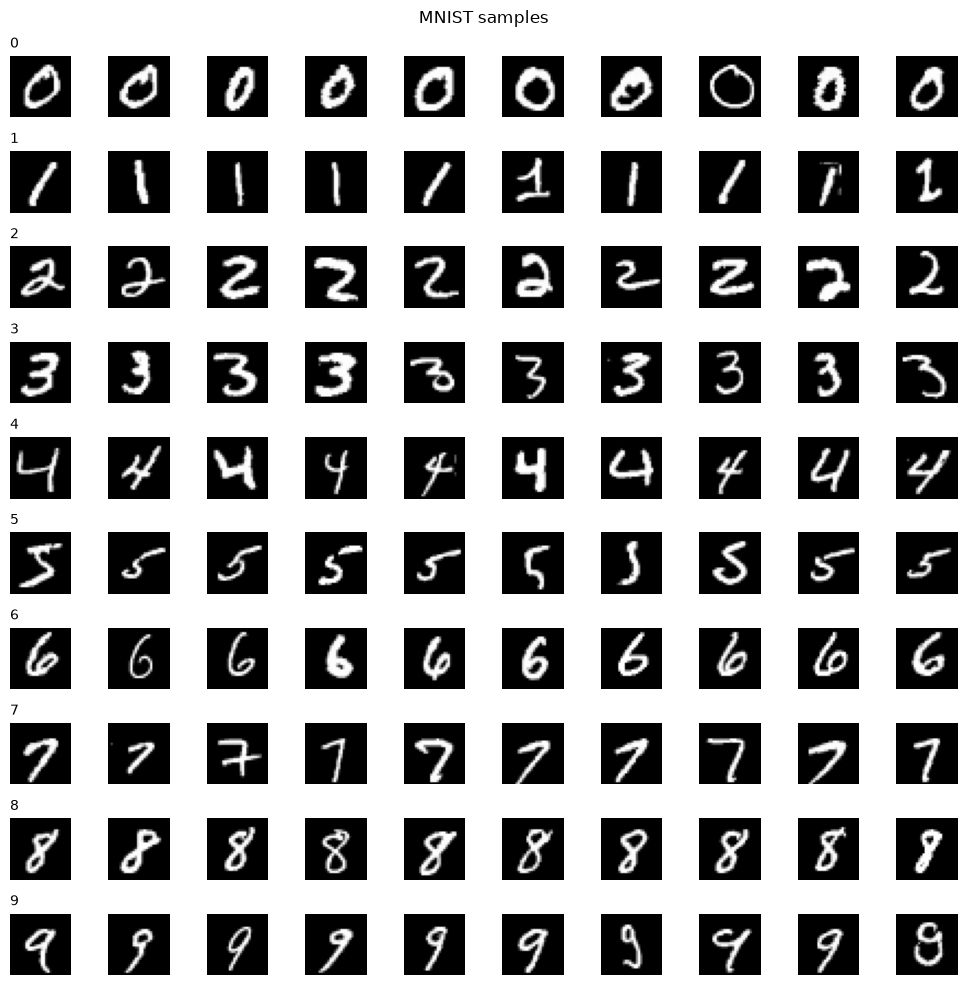

In [10]:
fig, axes = plt.subplots(10, 10, figsize=(10, 10))
for digit in range(10):
    imgs = x_train[y_train == digit][:10]
    for j in range(10):
        axes[digit, j].imshow(imgs[j], cmap='gray')
        axes[digit, j].axis('off')
    axes[digit, 0].set_title(str(digit), fontsize=10, loc='left')
plt.suptitle('MNIST samples')
plt.tight_layout()
plt.show()

### Class Distribution

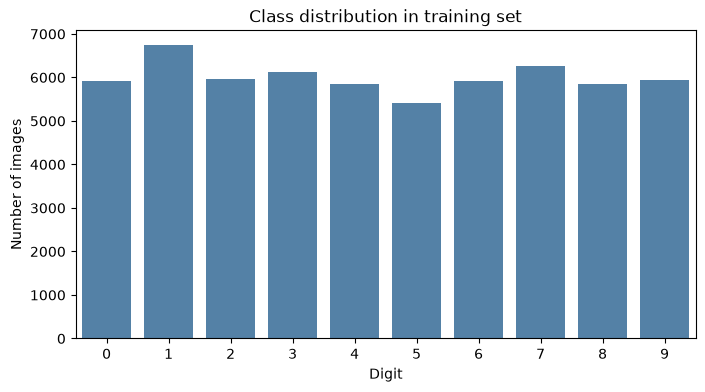

In [11]:
counts = pd.Series(y_train).value_counts().sort_index()
plt.figure(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values, color='steelblue')
plt.xlabel('Digit')
plt.ylabel('Number of images')
plt.title('Class distribution in training set')
plt.show()

In [12]:
small = counts.min()
large = counts.max()
print('Smallest class:', small, '| Largest class:', large)

Smallest class: 5421 | Largest class: 6742


# `Data Processing`

### Class Balancing

In [13]:
x_list = []
y_list = []
for digit in range(10):
    imgs = x_train[y_train == digit][:small]
    labels = y_train[y_train == digit][:small]
    x_list.append(imgs)
    y_list.append(labels)
x_bal = np.concatenate(x_list)
y_bal = np.concatenate(y_list)

print('x_bal shape:', x_bal.shape)
print('y_bal shape:', y_bal.shape)

x_bal shape: (54210, 28, 28)
y_bal shape: (54210,)


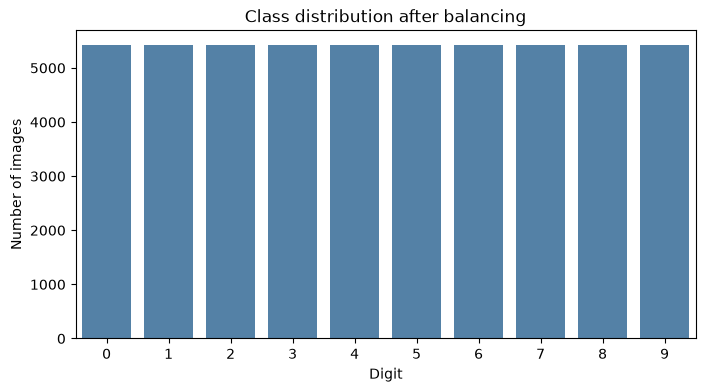

In [14]:
counts_bal = pd.Series(y_bal).value_counts().sort_index()
plt.figure(figsize=(8, 4))
sns.barplot(x=counts_bal.index, y=counts_bal.values, color='steelblue')
plt.xlabel('Digit')
plt.ylabel('Number of images')
plt.title('Class distribution after balancing')
plt.show()

### Normalizing Pixel Values Between(0-1)

In [15]:
x_bal = x_bal.astype('float32')/255.0
x_test = x_test.astype('float32')/255.0

### Cannel adding

In [16]:
x_bal = x_bal.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# `Tran | Validation`

In [17]:
x_tr, x_val, y_tr, y_val = train_test_split(x_bal, y_bal, test_size=0.2, random_state=42, stratify=y_bal)

print('Train:', x_tr.shape)
print('Validation:', x_val.shape)
print('Test:', x_test.shape)

Train: (43368, 28, 28, 1)
Validation: (10842, 28, 28, 1)
Test: (10000, 28, 28, 1)


# `CNN Model`

In [18]:
CNN = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

CNN.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [19]:
hist_cnn1 = CNN.fit(x_tr, y_tr, validation_data=(x_val, y_val), epochs=20, batch_size=128, verbose=2)

Epoch 1/20
339/339 - 27s - 81ms/step - accuracy: 0.9047 - loss: 0.3162 - val_accuracy: 0.9745 - val_loss: 0.0904
Epoch 2/20
339/339 - 41s - 121ms/step - accuracy: 0.9694 - loss: 0.0992 - val_accuracy: 0.9833 - val_loss: 0.0599
Epoch 3/20
339/339 - 27s - 78ms/step - accuracy: 0.9775 - loss: 0.0726 - val_accuracy: 0.9872 - val_loss: 0.0474
Epoch 4/20
339/339 - 28s - 83ms/step - accuracy: 0.9815 - loss: 0.0582 - val_accuracy: 0.9884 - val_loss: 0.0403
Epoch 5/20
339/339 - 35s - 104ms/step - accuracy: 0.9836 - loss: 0.0508 - val_accuracy: 0.9894 - val_loss: 0.0363
Epoch 6/20
339/339 - 48s - 143ms/step - accuracy: 0.9870 - loss: 0.0407 - val_accuracy: 0.9898 - val_loss: 0.0350
Epoch 7/20
339/339 - 90s - 265ms/step - accuracy: 0.9879 - loss: 0.0375 - val_accuracy: 0.9902 - val_loss: 0.0345
Epoch 8/20
339/339 - 74s - 218ms/step - accuracy: 0.9883 - loss: 0.0358 - val_accuracy: 0.9912 - val_loss: 0.0317
Epoch 9/20
339/339 - 122s - 361ms/step - accuracy: 0.9893 - loss: 0.0324 - val_accuracy: 0.

### Accuracy & Loss Curve

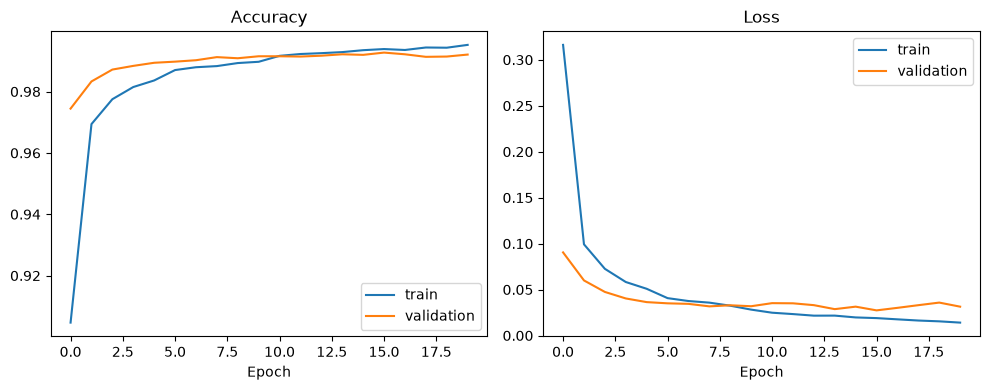

In [22]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(hist_cnn1.history['accuracy'], label='train')
plt.plot(hist_cnn1.history['val_accuracy'], label='validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_cnn1.history['loss'], label='train')
plt.plot(hist_cnn1.history['val_loss'], label='validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
y_prob = CNN.predict(x_test, verbose=0)
y_pred = y_prob.argmax(axis=1)

print('Test Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('Macro F1:', round(f1_score(y_test, y_pred, average='macro'), 4))
print(classification_report(y_test, y_pred, digits=4))

Test Accuracy: 0.9936
Macro F1: 0.9936
              precision    recall  f1-score   support

           0     0.9959    0.9980    0.9969       980
           1     0.9913    0.9982    0.9947      1135
           2     0.9942    0.9942    0.9942      1032
           3     0.9921    0.9931    0.9926      1010
           4     0.9959    0.9980    0.9969       982
           5     0.9899    0.9910    0.9905       892
           6     0.9989    0.9864    0.9926       958
           7     0.9922    0.9922    0.9922      1028
           8     0.9888    0.9959    0.9923       974
           9     0.9970    0.9881    0.9925      1009

    accuracy                         0.9936     10000
   macro avg     0.9936    0.9935    0.9936     10000
weighted avg     0.9936    0.9936    0.9936     10000



# `Correlation Matrix`

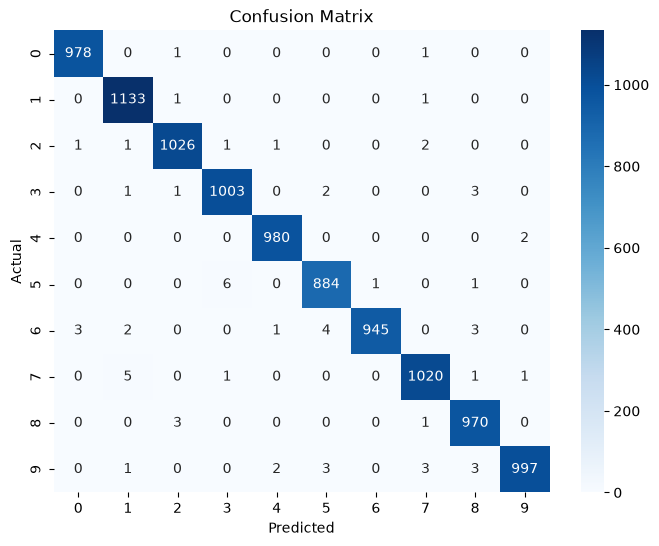

In [24]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [28]:
cm = confusion_matrix(y_test, y_pred)
cm2 = cm.copy()
np.fill_diagonal(cm2, 0)
rows = []
for i in range(10):
    for j in range(10):
        if cm2[i, j] > 0:
            rows.append({'Actual': i, 'Predicted': j, 'Count': cm2[i, j]})

pairs_df = pd.DataFrame(rows).sort_values('Count', ascending=False).reset_index(drop=True)
print('Total different pairs:', len(pairs_df))
pairs_df

Total different pairs: 33


,Actual,Predicted,Count
0,5,3,6
1,7,1,5
2,6,5,4
3,9,8,3
4,8,2,3
5,6,0,3
6,3,8,3
7,6,8,3
8,9,5,3
9,9,7,3


Total wrong: 64


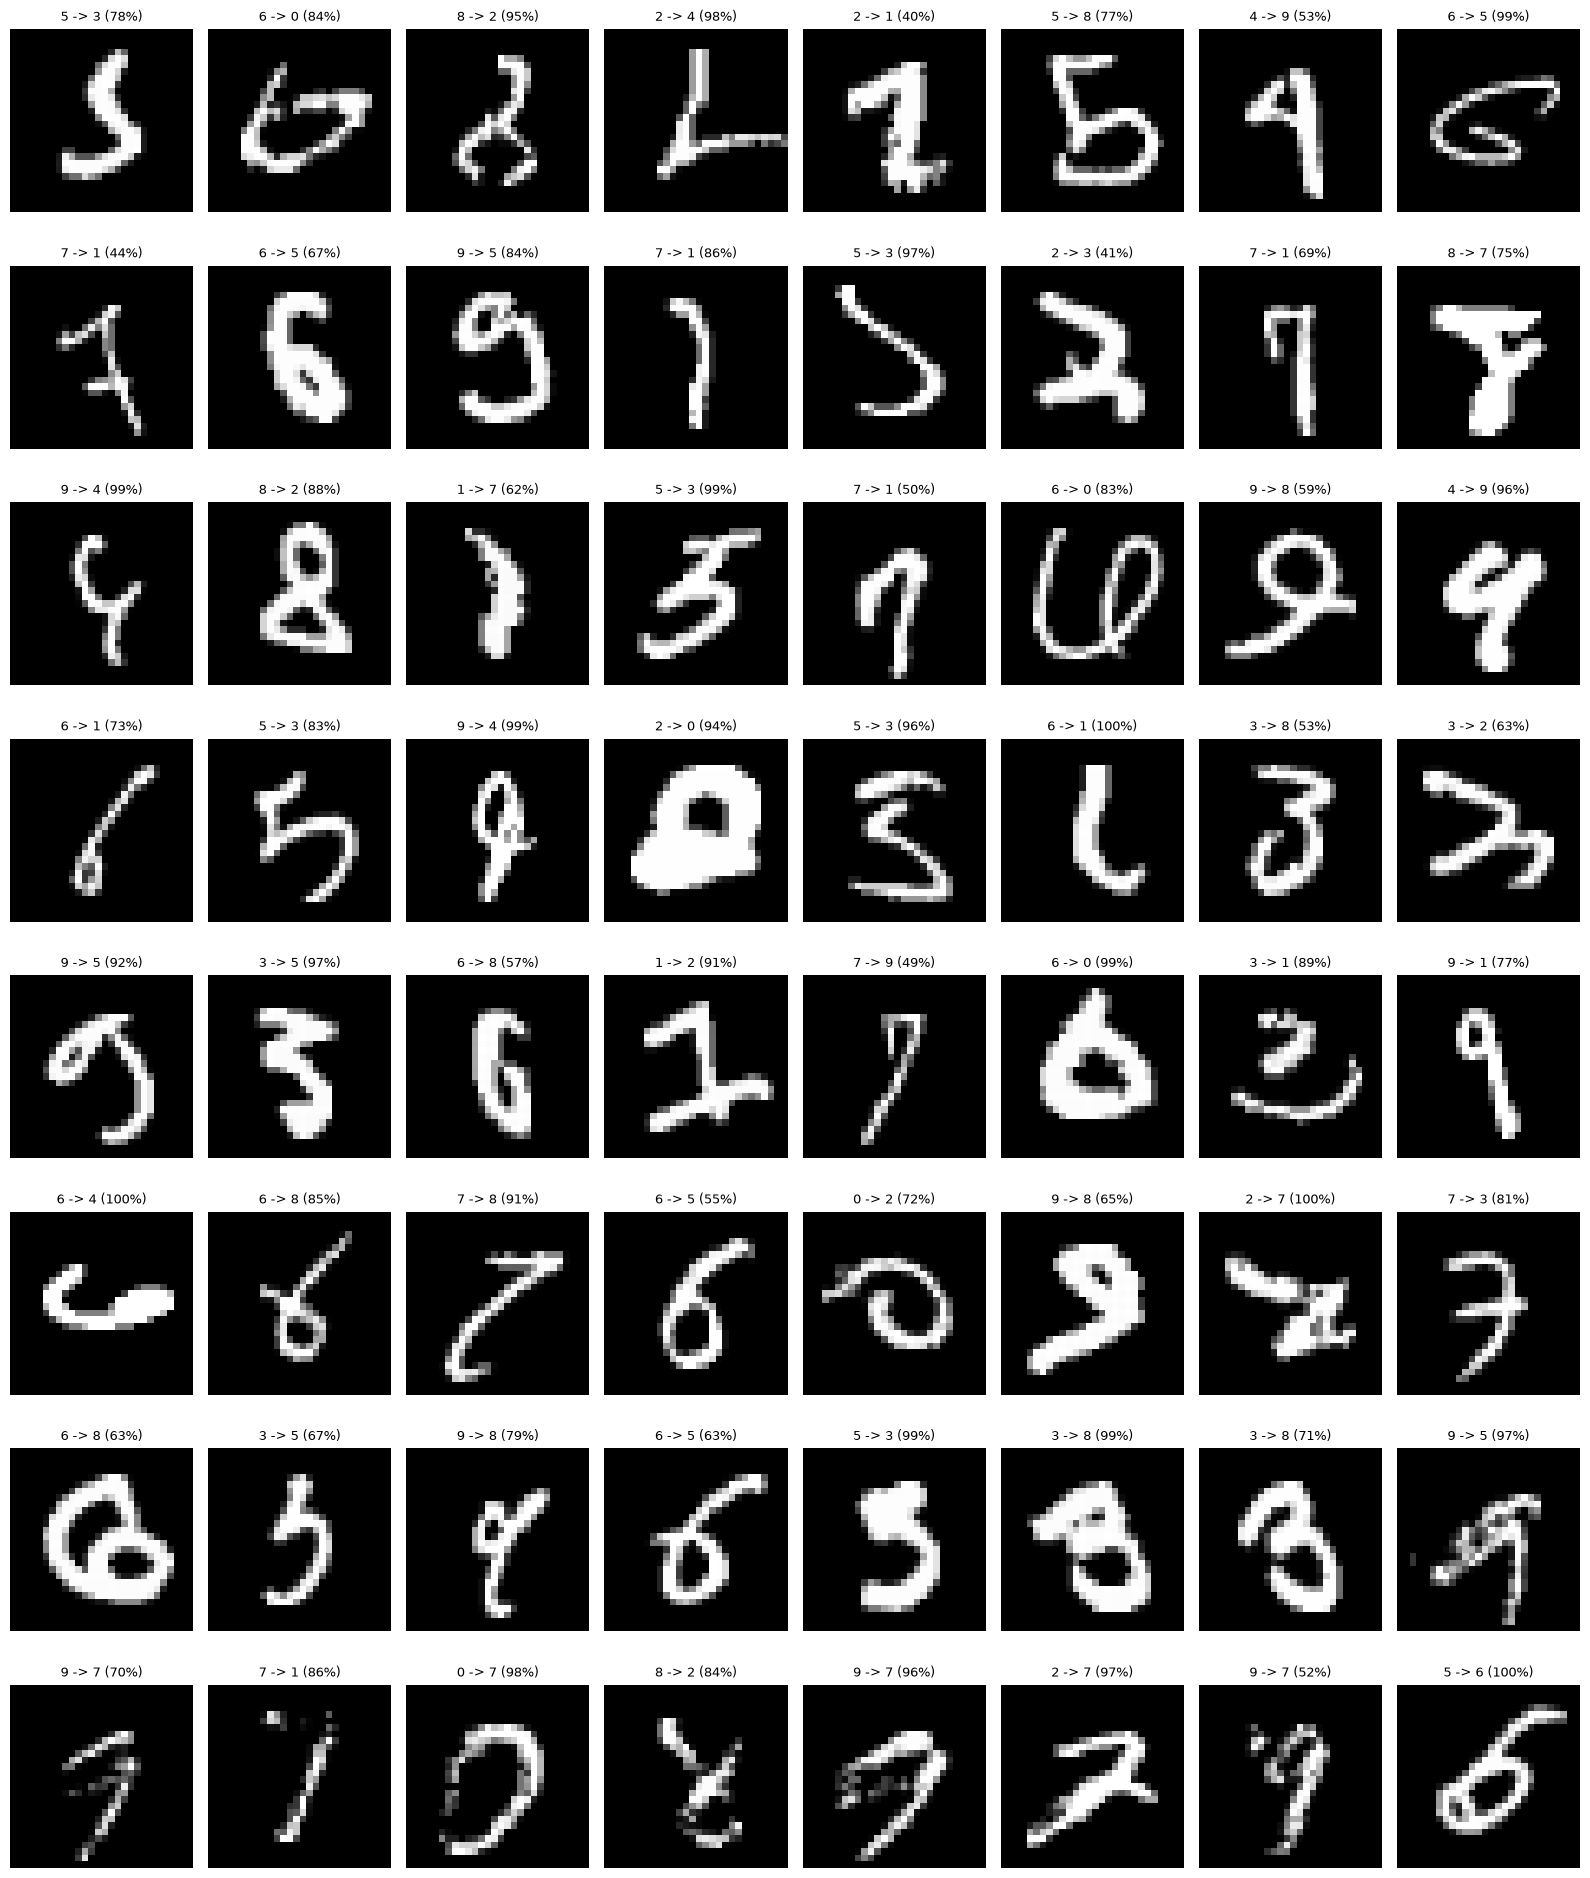

In [29]:
wrong = np.where(y_pred != y_test)[0]
print('Total wrong:', len(wrong))
cols = 8
n_rows = int(np.ceil(len(wrong) / cols))
fig, axes = plt.subplots(n_rows, cols, figsize=(cols * 2, n_rows * 2.4))
for ax in axes.flat:
    ax.axis('off')
for ax, idx in zip(axes.flat, wrong):
    ax.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    conf = y_prob[idx].max() * 100
    ax.set_title(str(y_test[idx]) + ' -> ' + str(y_pred[idx]) + ' (' + str(round(conf)) + '%)', fontsize=9)
plt.tight_layout()
plt.show()